# Audio results, errors and inference
These heldout numbers are saved historical results from ten recordings. This notebook never reads heldout targets or reruns scoring. It compares class errors, support, thresholds and the existing actual-waveform proof.

In [1]:
from pathlib import Path
import sys, json, math, hashlib, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
CACHE=ROOT/'data/features/five-second-cache'
FIGURES=ROOT/'assets/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=4)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def report(name): return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))

In [2]:
run=report('postprocess-v5-observed-holdout.json')
selected=pd.DataFrame(run['selected']['per_class']).set_index('class')
baseline=pd.DataFrame(run['five_second_baseline']['per_class']).set_index('class')
comparison=selected[['positive','observed','ap','f1']].rename(columns={'ap':'selected_AP','f1':'selected_F1'})
comparison['baseline_AP']=baseline['ap']; comparison['baseline_F1']=baseline['f1']
comparison['AP_delta']=comparison['selected_AP']-comparison['baseline_AP']; comparison['F1_delta']=comparison['selected_F1']-comparison['baseline_F1']
display(comparison)
metrics=['macro_ap_supported','macro_f1_all_observed_classes','macro_f1_supported','micro_f1']
display(pd.DataFrame({name:{metric:run[name][metric] for metric in metrics} for name in ('five_second_baseline','selected')}))

,positive,observed,selected_AP,selected_F1,baseline_AP,baseline_F1,AP_delta,F1_delta
class,,,,,,,,
announcement,0,483,NaN,0.000000,NaN,0.000000,NaN,0.000000
birds_singing,56,412,0.312558,0.497110,0.300663,0.477273,0.011895,0.019837
brakes_squeaking,55,481,0.201204,0.254980,0.198049,0.204593,0.003156,0.050387
car,689,893,0.960791,0.827862,0.958428,0.821918,0.002363,0.005944
cash register beeping,0,483,NaN,0.000000,NaN,0.000000,NaN,0.000000
children voices,113,2368,0.160958,0.243137,0.161946,0.260417,-0.000988,-0.017279
coffee machine,1,391,0.003534,0.005102,0.004082,0.005102,-0.000548,0.000000
cutlery and dishes,25,391,0.080198,0.000000,0.079478,0.000000,0.000720,0.000000
door opens/closes,0,601,NaN,0.000000,NaN,0.000000,NaN,0.000000


,five_second_baseline,selected
macro_ap_supported,0.395376,0.402975
macro_f1_all_observed_classes,0.294822,0.301531
macro_f1_supported,0.385537,0.394310
micro_f1,0.460607,0.471528


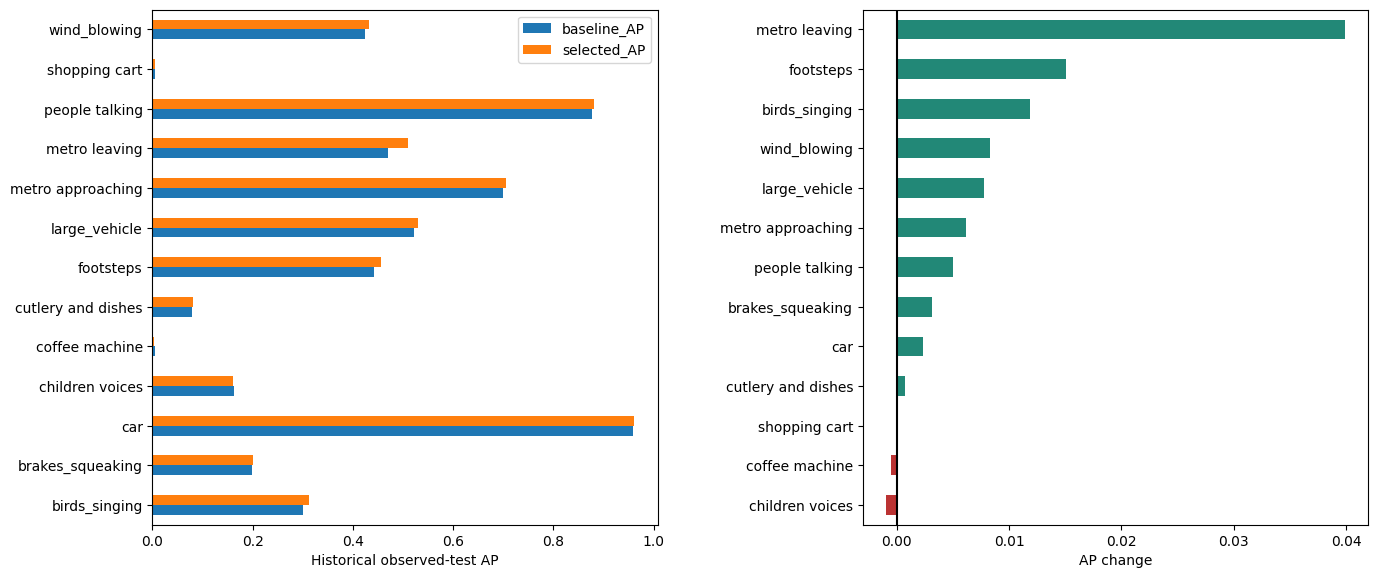

In [3]:
known=comparison[comparison['positive']>0]
fig,axes=plt.subplots(1,2,figsize=(14,6))
known[['baseline_AP','selected_AP']].plot.barh(ax=axes[0]); axes[0].set(xlabel='Historical observed-test AP',ylabel='')
delta=known['AP_delta'].sort_values()
delta.plot.barh(ax=axes[1],color=['#b33' if v<0 else '#287' for v in delta]); axes[1].axvline(0,color='black'); axes[1].set(xlabel='AP change',ylabel='')
show(fig,'audio_class_AP_and_changes.png')

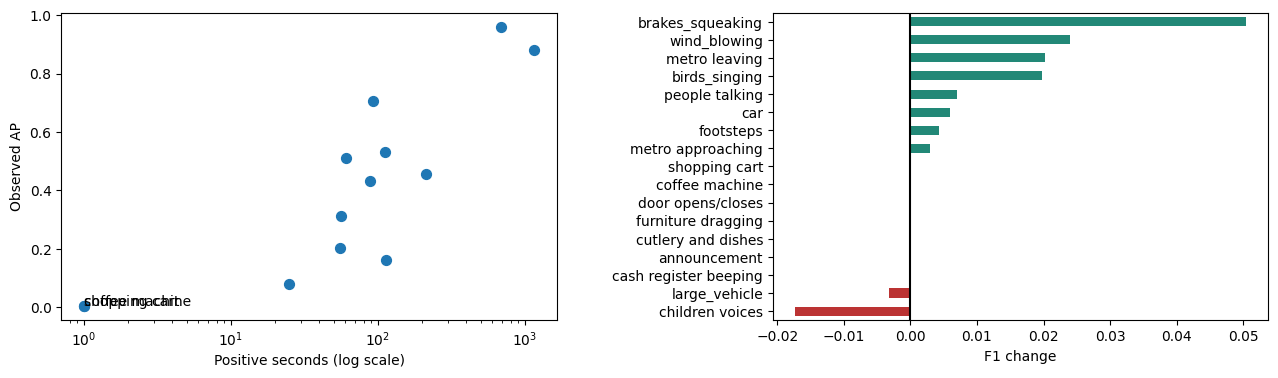

,positive,observed,selected_AP,selected_F1,baseline_AP,baseline_F1,AP_delta,F1_delta
class,,,,,,,,
children voices,113,2368,0.160958,0.243137,0.161946,0.260417,-0.000988,-0.017279
coffee machine,1,391,0.003534,0.005102,0.004082,0.005102,-0.000548,0.000000
large_vehicle,112,481,0.529848,0.472527,0.522126,0.475676,0.007722,-0.003148
shopping cart,1,483,0.005348,0.004132,0.005376,0.004132,-0.000029,0.000000


AP undefined for: ['announcement', 'cash register beeping', 'door opens/closes', 'furniture dragging']


In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].scatter(known['positive'],known['selected_AP'],s=50)
for label,row in known.iterrows():
    if row['positive']<10: axes[0].annotate(label,(row['positive'],row['selected_AP']))
axes[0].set_xscale('log'); axes[0].set(xlabel='Positive seconds (log scale)',ylabel='Observed AP')
delta=comparison['F1_delta'].sort_values()
delta.plot.barh(ax=axes[1],color=['#b33' if v<0 else '#287' for v in delta]); axes[1].axvline(0,color='black'); axes[1].set(xlabel='F1 change',ylabel='')
show(fig,'audio_support_and_F1_errors.png')
display(comparison[(comparison['AP_delta']<0)|(comparison['F1_delta']<0)])
print('AP undefined for:',comparison.index[comparison['positive']==0].tolist())

Smoothing improves aggregate AP and micro F1, but children voices, coffee machine and shopping cart lose AP. Coffee/cart each have one positive second. Children voices and large vehicles lose F1. Unsupported classes remain visible rather than receiving a favorable score.

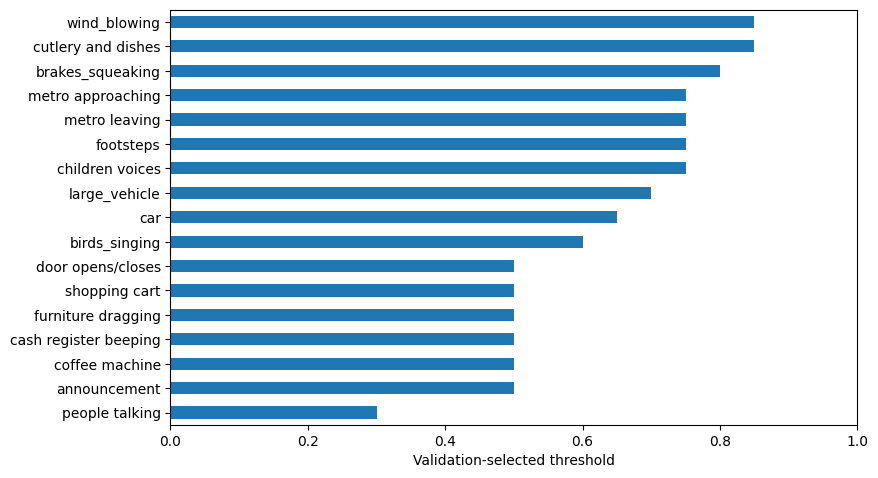

{'active_branches': 1, 'retained_components': 1, 'lookahead_seconds': 3}


In [5]:
policy=report('postprocess-v5-selection.json')
metadata=json.loads((CACHE/'metadata.json').read_text(encoding='utf-8'))
thresholds=pd.Series(policy['thresholds'],index=metadata['classes'],name='Validation-selected threshold')
fig,ax=plt.subplots(figsize=(9,5)); thresholds.sort_values().plot.barh(ax=ax); ax.set(xlabel=thresholds.name,ylabel='',xlim=(0,1)); show(fig,'audio_validation_thresholds.png')
print({'active_branches':len(policy['selected_policy']['branches']),'retained_components':len(policy['retained_component_indices']),'lookahead_seconds':policy['lookahead_seconds']})

## Actual waveform proof
The private GPU runner processed a licensed waveform. This verifies inference mechanics, not a new accuracy estimate.

In [6]:
proof=report('postprocess-v5-actual-inference-proof.json')
receipt=report('production-checkpoint-receipt.json')
display(pd.DataFrame([proof])); display(pd.DataFrame([receipt]))
assert proof['finite_in_unit_interval'] and proof['checkpoint_replay_max_difference']==0
assert receipt['v6_saved_state_exactly_equal_to_production']

,rows,probabilities,finite_in_unit_interval,probe_source_record,accuracy_claim,lookahead_seconds,checkpoint_replay_max_difference
0,5,85,True,cafe_restaurant_04,False,3,0.0


,production_checkpoint,production_sha256,v6_saved_state_exactly_equal_to_production,actual_cli_validation_ap,actual_cli_validation_matches_frozen_selection,v6_cached_checkpoint_replay_max_difference,production_waveform_inference,new_encoder_training,new_head_promoted,python,torch,study_device,torch_threads
0,models/postprocess-v5/selected.pt,d082cb659e8ab94b9661fca741630cf12e09b951aa7ec7...,True,0.476702,True,0.0,Completed on V5 private GPU; docs/postprocess-...,False,False,3.14.2,2.14.0+cpu,CPU,2


## Optional new recording
Provide your own licensed audio and a fresh path. This prediction has no labels and never performs model selection.

In [7]:
RUN_NEW_WAVEFORM=False
if RUN_NEW_WAVEFORM:
    from overlap_audio.postprocess import infer
    output=ROOT/'data'/('prediction-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')+'.json')
    if output.exists(): raise FileExistsError(output)
    result=infer(ROOT/'models/postprocess-v5/selected.pt',ROOT/'data/external/panns/Cnn14.pth',ROOT/'data/my-recording.wav',output,'cpu')
    print({'seconds':len(result['observations']),'lookahead_seconds':result['lookahead_seconds']})

Three seconds of future context and a small custom split limit deployment conclusions. These results do not establish immediate streaming, new-location transfer or reliable rare-class detection.